# ADP 20회 실기 - 문항별 풀이 노트북

첨부 DataManim PDF의 **모든 세부 문항**을 원문과 함께 수록하고 독립적으로 작성한 예시 풀이입니다. 공식 정답지가 아닙니다. 데이터·그래프·평가표·가설검정 수치가 실행 결과로 포함됩니다.

**실행:** 압축 전체를 해제하고 이 노트북이 있는 `20회` 폴더에서 위에서 아래로 실행하세요. `data/`의 원자료를 읽으며 다운로드를 하지 않습니다. 재실행 결과는 `실행결과/`에 저장됩니다. Python 3.12 환경에서 실행 검증하며 Python 3.7용 의존성 안내도 별도로 제공합니다.

**평가 원칙:** 학습 구간에서만 대치·스케일링·변수 선택·리샘플링을 적합합니다. 모델·임계값 선택은 validation으로 하고 최종 test는 보류합니다. 시계열은 시간 순 분할을 사용합니다. 실행 시간은 기기와 반복 실행에 따라 달라집니다.

In [1]:
from pathlib import Path
import sys, platform, time, inspect, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown
from scipy import stats
import statsmodels.api as sm
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression, RidgeCV
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVC, SVR
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix,
    roc_auc_score, average_precision_score, mean_squared_error, mean_absolute_error, r2_score,
    silhouette_score)
from sklearn.inspection import permutation_importance
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.oneway import anova_oneway
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

SEED = 42
HERE = Path.cwd()
DATA = HERE / 'data'
assert DATA.is_dir(), '압축을 전체 해제한 뒤, 노트북이 있는 회차 폴더를 작업 위치로 실행하세요.'
OUT = HERE / '실행결과'
OUT.mkdir(exist_ok=True)
font_path = HERE.parent / '공통' / 'NanumGothic-Regular.ttf'
if font_path.is_file():
    font_manager.fontManager.addfont(str(font_path))
    plt.rcParams['font.family'] = font_manager.FontProperties(fname=str(font_path)).get_name()
plt.rcParams.update({'axes.unicode_minus': False, 'figure.dpi': 110, 'font.size': 10})
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_rows', 20)
print('Python', platform.python_version())
import sklearn, scipy, statsmodels, imblearn
print('numpy', np.__version__, 'pandas', pd.__version__, 'scikit-learn', sklearn.__version__,
      'scipy', scipy.__version__, 'statsmodels', statsmodels.__version__, 'imblearn', imblearn.__version__)

def load(name):
    return pd.read_csv(DATA / name if (DATA / name).exists() else DATA / (name + ".gz"))

def ohe():
    return OneHotEncoder(handle_unknown='ignore', **({'sparse_output': False} if 'sparse_output' in inspect.signature(OneHotEncoder).parameters else {'sparse': False}))

def reg_metrics(actual, predicted):
    a, b = np.asarray(actual, dtype=float), np.asarray(predicted, dtype=float)
    assert a.shape == b.shape and np.isfinite(a).all() and np.isfinite(b).all()
    mask = a != 0
    return {'MSE': mean_squared_error(a,b), 'RMSE': np.sqrt(mean_squared_error(a,b)),
            'MAE': mean_absolute_error(a,b), 'MAPE(%)': 100*np.mean(np.abs((a[mask]-b[mask])/a[mask])) if mask.any() else np.nan,
            'MAPE 제외 0개수': int((~mask).sum()), 'R2': r2_score(a,b)}

def class_metrics(actual, predicted, probability=None):
    a, b = np.asarray(actual), np.asarray(predicted)
    assert a.shape == b.shape
    result = {'Accuracy':accuracy_score(a,b), 'BalancedAccuracy':balanced_accuracy_score(a,b),
              'F1_macro':f1_score(a,b,average='macro',zero_division=0),
              'F1_weighted':f1_score(a,b,average='weighted',zero_division=0)}
    if probability is not None and set(np.unique(a)) == {0,1}:
        score = np.asarray(probability)
        score = score[:,1] if score.ndim == 2 else score
        result.update(ROC_AUC=roc_auc_score(a,score), AveragePrecision=average_precision_score(a,score))
    return result

def decision(p, alpha=.05):
    return '귀무가설 기각' if p < alpha else '귀무가설을 기각할 근거 부족'

def quality(frame):
    display(pd.DataFrame({'dtype':frame.dtypes.astype(str), 'missing':frame.isna().sum(), 'unique':frame.nunique()}))
    print('shape:', frame.shape, 'duplicate rows:', frame.duplicated().sum())
    display(frame.describe(include='all').T)

def plot_confusion(actual, prediction, labels=None, title='Confusion matrix'):
    order = np.unique(np.r_[actual,prediction]) if labels is None else labels
    matrix=confusion_matrix(actual,prediction,labels=order)
    fig,ax=plt.subplots(figsize=(5,4));im=ax.imshow(matrix,cmap='Blues')
    ax.set(xticks=range(len(order)),yticks=range(len(order)),xticklabels=order,yticklabels=order,
           xlabel='예측',ylabel='실제',title=title)
    for (i,j),value in np.ndenumerate(matrix):
        ax.text(j,i,int(value),ha='center',va='center',color='white' if value>matrix.max()/2 else 'black')
    fig.colorbar(im,ax=ax);fig.tight_layout();plt.show()
    return pd.DataFrame(matrix,index=order,columns=order)

def median_predict_time(model, X, repeat=5):
    model.predict(X)
    elapsed=[]
    for _ in range(repeat):
        start=time.perf_counter();model.predict(X);elapsed.append(time.perf_counter()-start)
    return float(np.median(elapsed))

class IQRClipper(TransformerMixin, BaseEstimator):
    def __init__(self, factor=1.5): self.factor=factor
    def fit(self, X, y=None):
        q1,q3=np.percentile(np.asarray(X,dtype=float),[25,75],axis=0)
        self.lower_=q1-self.factor*(q3-q1);self.upper_=q3+self.factor*(q3-q1)
        return self
    def transform(self, X): return np.clip(np.asarray(X,dtype=float),self.lower_,self.upper_)

Python 3.12.14
numpy 2.3.5 pandas 2.2.3 scikit-learn 1.8.0 scipy 1.17.0 statsmodels 0.14.6 imblearn 0.14.2


## 1번 | 날씨 온도 예측

날씨 온도 예측, 종속변수 :actual(최고온도)

데이터 출처 : https://towardsdatascience.com/random-forest-in-python-24d0893d51c0

데이터 경로 : /kaggle/input/adp-kr-p2/problem1.csv

temp_1 : 전날 최고온도 / temp_2 : 전전날 최고온도 / friend : 친구의 예측온도

### 1-1

> 데이터 확인 및 전처리
> 데이터 EDA 수행
> 결측치를 확인하고 처리 방안에 대해 논의하라
> 데이터 분할 방법 설명
> 최종 데이터셋이 적절함을 주장하라

**풀이 및 해석**

연·월·일로 날짜를 만들고 시간 순으로 train 60%, validation 20%, test 20%를 분리합니다. week는 one-hot, 수치형은 train 중앙값 대치와 표준화로 처리합니다. 최고온도·직전 최고온도와의 관계, 결측·중복·날짜 순서를 확인합니다. 예측 시점에 이용 가능한 사전 예보값이라는 가정 아래 forecast/friend를 사용하며, 당시 이용할 수 없던 값이라면 제외해야 합니다.

,dtype,missing,unique
year,int64,0,1
month,int64,0,12
day,int64,0,31
week,object,0,7
temp_2,int64,0,56
temp_1,int64,0,56
average,float64,0,243
actual,int64,0,55
forecast_noaa,int64,0,37
forecast_acc,int64,0,37


shape: (348, 13) duplicate rows: 0


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
year,348.0,NaN,NaN,NaN,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,0.0
month,348.0,NaN,NaN,NaN,6.477011,1.0,3.0,6.0,10.0,12.0,3.49838
day,348.0,NaN,NaN,NaN,15.514368,1.0,8.0,15.0,23.0,31.0,8.772982
week,348,7,Tues,52,NaN,NaN,NaN,NaN,NaN,NaN,NaN
temp_2,348.0,NaN,NaN,NaN,62.652299,35.0,54.0,62.5,71.0,117.0,12.165398
temp_1,348.0,NaN,NaN,NaN,62.701149,35.0,54.0,62.5,71.0,117.0,12.120542
average,348.0,NaN,NaN,NaN,59.760632,45.1,49.975,58.2,69.025,77.4,10.527306
actual,348.0,NaN,NaN,NaN,62.543103,35.0,54.0,62.5,71.0,92.0,11.794146
forecast_noaa,348.0,NaN,NaN,NaN,57.238506,41.0,48.0,56.0,66.0,77.0,10.605746
forecast_acc,348.0,NaN,NaN,NaN,62.373563,46.0,53.0,61.0,72.0,82.0,10.549381


,set,rows,start,end
0,train,208,2016-01-01,2016-07-29
1,validation,70,2016-07-30,2016-10-21
2,test,70,2016-10-22,2016-12-31


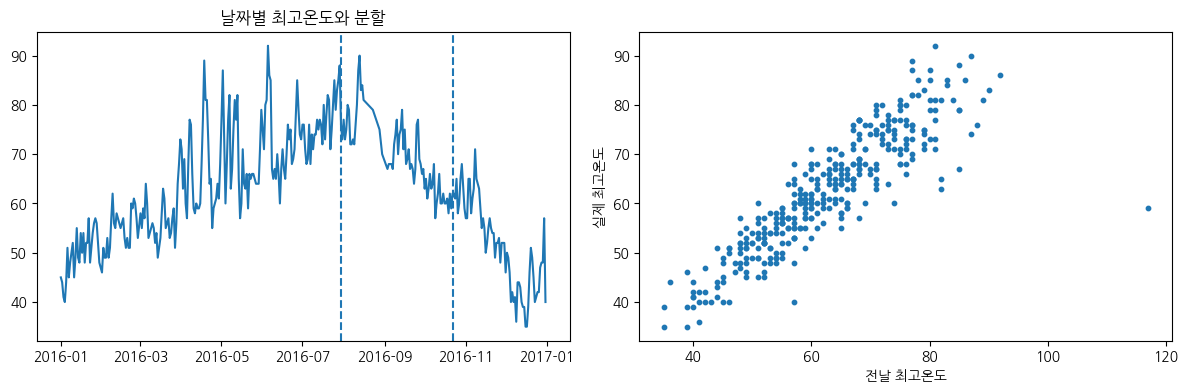

In [2]:
temperatures=load('problem1.csv');temperatures['date']=pd.to_datetime(temperatures[['year','month','day']]);temperatures=temperatures.sort_values('date').reset_index(drop=True)
quality(temperatures)
assert temperatures.date.is_unique
X=temperatures.drop(columns=['actual','date']);y=temperatures.actual.to_numpy()
n=len(temperatures);a=int(n*.6);c=int(n*.8);train_idx=np.arange(a);valid_idx=np.arange(a,c);test_idx=np.arange(c,n)
numeric_columns=X.select_dtypes('number').columns.tolist();categorical_columns=X.select_dtypes(exclude='number').columns.tolist()
def temp_preprocess():
    return ColumnTransformer([('numeric',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),numeric_columns),
                              ('category',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('encode',ohe())]),categorical_columns)],sparse_threshold=0)
display(pd.DataFrame({'set':['train','validation','test'],'rows':[len(train_idx),len(valid_idx),len(test_idx)],
                     'start':[temperatures.date.iloc[i[0]] for i in [train_idx,valid_idx,test_idx]],'end':[temperatures.date.iloc[i[-1]] for i in [train_idx,valid_idx,test_idx]]}))
fig,axs=plt.subplots(1,2,figsize=(12,4));axs[0].plot(temperatures.date,y);axs[0].axvline(temperatures.date.iloc[a],ls='--');axs[0].axvline(temperatures.date.iloc[c],ls='--');axs[0].set_title('날짜별 최고온도와 분할')
axs[1].scatter(temperatures.temp_1,temperatures.actual,s=10);axs[1].set(xlabel='전날 최고온도',ylabel='실제 최고온도');fig.tight_layout();plt.show()

### 1-2

> Random Forest 모델 적합 및 검증
> Random Forest 학습 및 예측 결과 해석
> 예측 결과 검정 해석, 중요변수 도출
> 변수 중요성 분석 및 그래프 출력

**풀이 및 해석**

Random Forest는 비선형 관계·상호작용을 포착하고 평균화로 단일 트리의 분산을 낮춥니다. train과 validation의 회귀 오차를 함께 확인하고, 원 변수의 permutation importance를 validation에서 측정합니다. 불순도 중요도는 후보 수가 많은 변수에 편향될 수 있어 이것만으로 중요성을 단정하지 않습니다.

,MSE,RMSE,MAE,MAPE(%),MAPE 제외 0개수,R2
train,5.763770,2.400785,1.908587,2.969453,0.0,0.954279
validation,22.426449,4.735657,3.809418,5.430641,0.0,0.577289


,mean,std
day,-0.773892,0.402348
temp_2,-0.190972,0.427836
forecast_noaa,-0.078946,0.311171
year,0.000000,0.000000
month,0.000000,0.000000
week,0.076873,0.799987
forecast_acc,0.222746,0.501617
friend,0.891478,0.593912
forecast_under,1.108713,0.742065
average,1.783874,0.717844


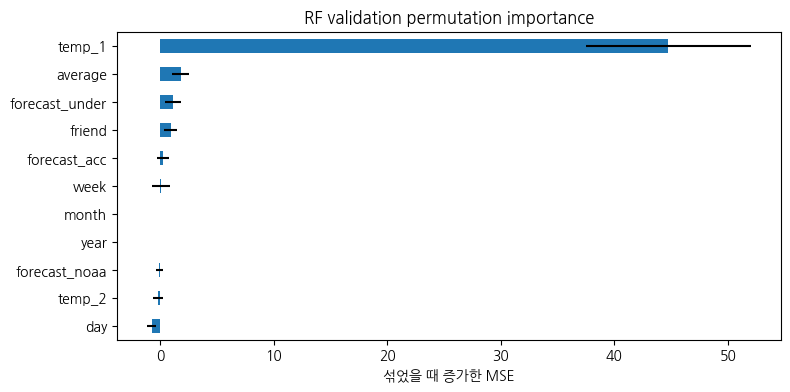

In [3]:
rf=Pipeline([('preprocess',temp_preprocess()),('model',RandomForestRegressor(n_estimators=180,min_samples_leaf=2,random_state=SEED,n_jobs=1))])
start=time.perf_counter();rf.fit(X.iloc[train_idx],y[train_idx]);rf_time=time.perf_counter()-start
rf_valid=rf.predict(X.iloc[valid_idx]);rf_results=reg_metrics(y[valid_idx],rf_valid)
display(pd.DataFrame({'train':reg_metrics(y[train_idx],rf.predict(X.iloc[train_idx])),'validation':rf_results}).T)
rf_importance=permutation_importance(rf,X.iloc[valid_idx],y[valid_idx],scoring='neg_mean_squared_error',n_repeats=10,random_state=SEED)
rf_table=pd.DataFrame({'mean':rf_importance.importances_mean,'std':rf_importance.importances_std},index=X.columns).sort_values('mean')
display(rf_table)
fig,ax=plt.subplots(figsize=(8,4));rf_table['mean'].plot.barh(xerr=rf_table['std'],ax=ax);ax.set(title='RF validation permutation importance',xlabel='섞었을 때 증가한 MSE');fig.tight_layout();plt.show()

### 1-3

> SVM(Support Vector Machine) 모델 적합 및 검증
> svm 학습 및 예측 결과 해석
> 예측 결과 검정 해석, 중요변수 도출
> 변수 중요성 분석 및 그래프 출력

**풀이 및 해석**

온도는 연속형이므로 분류 SVC가 아니라 회귀 SVR(RBF)을 사용합니다. 거리 기반 모형에 필요한 스케일은 train에서만 적합합니다. RBF SVR에는 일반적인 선형 계수 중요도가 없으므로 모델 독립적인 permutation importance를 제시합니다. 검증 오차·학습 시간·예측 시간을 RF와 같은 조건에서 측정합니다.

,MSE,RMSE,MAE,MAPE(%),MAPE 제외 0개수,R2
train,13.105550,3.620159,2.303698,3.553048,0.0,0.896041
validation,23.906154,4.889392,4.015423,5.867913,0.0,0.549399


,mean,std
forecast_noaa,-1.442065,0.984867
forecast_acc,-0.548393,0.859480
forecast_under,-0.112594,1.180993
year,0.000000,0.000000
day,0.168409,1.523946
temp_2,0.700280,0.698931
average,0.759233,1.120975
week,1.719600,0.889004
friend,1.986733,1.502475
month,3.646160,0.442738


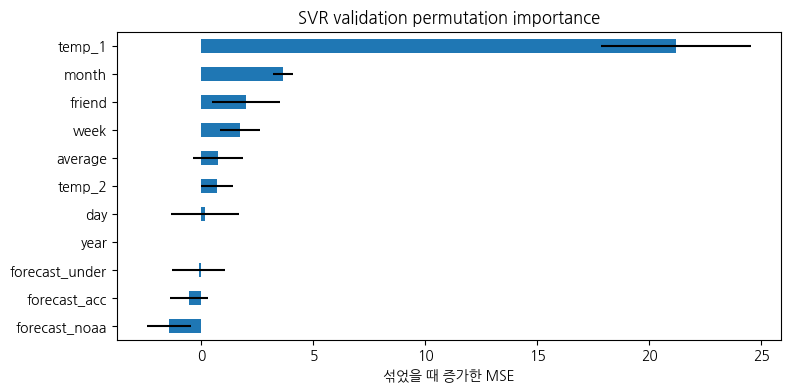

In [4]:
svr=Pipeline([('preprocess',temp_preprocess()),('model',SVR(C=20,epsilon=.1,kernel='rbf'))])
start=time.perf_counter();svr.fit(X.iloc[train_idx],y[train_idx]);svr_time=time.perf_counter()-start
svr_valid=svr.predict(X.iloc[valid_idx]);svr_results=reg_metrics(y[valid_idx],svr_valid)
display(pd.DataFrame({'train':reg_metrics(y[train_idx],svr.predict(X.iloc[train_idx])),'validation':svr_results}).T)
svr_importance=permutation_importance(svr,X.iloc[valid_idx],y[valid_idx],scoring='neg_mean_squared_error',n_repeats=10,random_state=SEED)
svr_table=pd.DataFrame({'mean':svr_importance.importances_mean,'std':svr_importance.importances_std},index=X.columns).sort_values('mean');display(svr_table)
fig,ax=plt.subplots(figsize=(8,4));svr_table['mean'].plot.barh(xerr=svr_table['std'],ax=ax);ax.set(title='SVR validation permutation importance',xlabel='섞었을 때 증가한 MSE');fig.tight_layout();plt.show()

### 1-4

> 모델 비교 및 향후 개선 방향 도출
> Random Forest, SVM 모델의 결과 비교 후 최종 모델 선택
> 두 모델의 장단점 분석, 추후 운영 관점에서 어떤 모델을 선택할 것인가?
> 모델링 관련 추후 개선 방향 제시

**풀이 및 해석**

validation RMSE가 낮은 모형을 선택하되 학습·예측 시간도 운영 판단에 보고합니다. RF는 상호작용과 중요도 분석이 편하지만 학습·메모리 비용이 있고, RBF SVR은 스케일에 민감하며 큰 데이터에서 비용이 커질 수 있습니다. 오차 차이의 H0를 기대 제곱오차 차이=0으로 두고 시간 의존성을 고려한 7일 이동 블록 부트스트랩 95% 구간을 보조로 제시합니다. 향후에는 rolling CV·계절성·누락 날짜·예보 이용 가능 시점·드리프트·주기적 재학습을 검토합니다.

In [5]:
comparison=pd.DataFrame([{'model':'RF',**rf_results,'fit_seconds':rf_time,'predict_seconds':median_predict_time(rf,X.iloc[valid_idx])},
                         {'model':'SVR',**svr_results,'fit_seconds':svr_time,'predict_seconds':median_predict_time(svr,X.iloc[valid_idx])}]).set_index('model')
display(comparison)
loss_difference=(y[valid_idx]-rf_valid)**2-(y[valid_idx]-svr_valid)**2
rng=np.random.RandomState(SEED);block_length=7;m=len(loss_difference);bootstrap=[]
for _ in range(1000):
    starts=rng.randint(0,m-block_length+1,size=int(np.ceil(m/block_length)))
    sample=np.concatenate([loss_difference[i:i+block_length] for i in starts])[:m];bootstrap.append(sample.mean())
interval=np.percentile(bootstrap,[2.5,97.5]);print('RF MSE − SVR MSE:',loss_difference.mean(),'7일 블록 bootstrap 95% 구간:',interval)
print('0을 포함하면 오차 차이가 있다는 근거가 부족합니다. 블록 길이·표본 기간 가정에 민감합니다.')
selected_name=comparison.RMSE.idxmin();final_model={'RF':rf,'SVR':svr}[selected_name]
print('선택:',selected_name);display(pd.Series(reg_metrics(y[test_idx],final_model.predict(X.iloc[test_idx])),name='최종 test'))
comparison.to_csv(OUT/'온도_모델_validation비교.csv')

,MSE,RMSE,MAE,MAPE(%),MAPE 제외 0개수,R2,fit_seconds,predict_seconds
model,,,,,,,,
RF,22.426449,4.735657,3.809418,5.430641,0,0.577289,0.225905,0.010426
SVR,23.906154,4.889392,4.015423,5.867913,0,0.549399,0.010262,0.002813


RF MSE − SVR MSE: -1.4797049156410318 7일 블록 bootstrap 95% 구간: [-8.29171589  6.11665216]
0을 포함하면 오차 차이가 있다는 근거가 부족합니다. 블록 길이·표본 기간 가정에 민감합니다.
선택: RF


MSE            26.358450
RMSE            5.134048
MAE             3.724479
MAPE(%)         7.791447
MAPE 제외 0개수     0.000000
R2              0.674902
Name: 최종 test, dtype: float64

## 2번 | 가구별 전력 사용량

5분간격의 가구별 전력 사용량의 데이터

데이터 출처 : 자체생성

데이터 경로 : https://raw.githubusercontent.com/Datamanim/datarepo/main/adp/p2/problem2.csv

### 2-1

> 데이터 전처리
> 각 가구의 15분간격의 전력량의 합을 구하고 해당데이터를 바탕으로 총 5개의 군집으로 군집화를 진행한 후 아래의 그림과 같은 형태로 출력하라.
> 군집화를 위한 데이터 구성의 이유를 설명하라
> (군집 방식에 따라 Cluster컬럼의 값은 달라질수 있음)

**풀이 및 해석**

5분 레코드 3개를 같은 가구·15분 구간으로 합칩니다. 원문 표에서 같은 가구의 군집이 시간에 따라 바뀌므로, 이 예제는 가구 전체를 한 군집에 고정하지 않고 가구×15분 레코드의 사용량 수준을 5개 군집으로 구분합니다. target이나 식별자·날짜의 숫자를 거리 변수로 쓰지 않습니다. 군집 번호는 소비 중심이 낮은 순서로 재표기하며 원문처럼 번호 자체는 달라질 수 있습니다.

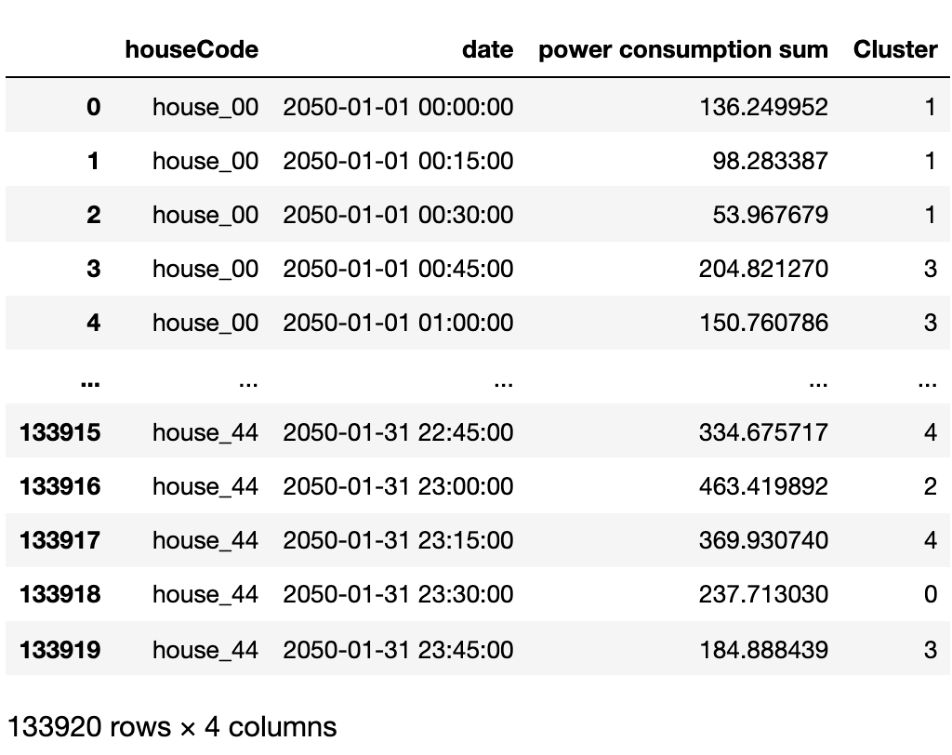

In [6]:
power=load('problem2.csv');power['date']=pd.to_datetime(power.date);power=power.sort_values(['houseCode','date'])
assert not power.duplicated(['houseCode','date']).any()
counts=power.set_index('date').groupby('houseCode')['power consumption'].resample('15min').count()
assert counts.eq(3).all(), '누락·중복 5분 구간을 먼저 처리해야 합니다.'
quarter=power.set_index('date').groupby('houseCode')['power consumption'].resample('15min').sum(min_count=1).rename('power consumption sum').reset_index()
assert len(quarter)==133920
np.testing.assert_allclose(quarter['power consumption sum'].sum(),power['power consumption'].sum())
scaler=StandardScaler().fit(quarter[['power consumption sum']]);coordinates=scaler.transform(quarter[['power consumption sum']])
km=KMeans(n_clusters=5,n_init=10,random_state=SEED).fit(coordinates)
center_order=np.argsort(km.cluster_centers_.ravel());mapping={int(old):int(new) for new,old in enumerate(center_order)}
quarter['Cluster']=pd.Series(km.labels_).map(mapping).to_numpy()
display(quarter.head());display(quarter.tail());display(quarter.groupby('Cluster')['power consumption sum'].agg(['size','mean','min','max']))
quarter.to_csv(OUT/'가구_15분전력_군집.csv',index=False)
print('원문과 같은 출력 크기:',quarter.shape)

,houseCode,date,power consumption sum,Cluster
0,house_00,2050-01-01 00:00:00,136.249952,0
1,house_00,2050-01-01 00:15:00,98.283387,0
2,house_00,2050-01-01 00:30:00,53.967679,0
3,house_00,2050-01-01 00:45:00,204.821270,1
4,house_00,2050-01-01 01:00:00,150.760786,1


,houseCode,date,power consumption sum,Cluster
133915,house_44,2050-01-31 22:45:00,334.675717,3
133916,house_44,2050-01-31 23:00:00,463.419892,4
133917,house_44,2050-01-31 23:15:00,369.930740,3
133918,house_44,2050-01-31 23:30:00,237.713030,2
133919,house_44,2050-01-31 23:45:00,184.888439,1


,size,mean,min,max
Cluster,,,,
0,25589,104.629754,6.003680,144.751824
1,38773,185.463528,144.754687,223.698987
2,36570,262.424034,223.702041,305.775754
3,24343,349.196298,305.776629,408.972424
4,8645,468.404162,408.978713,900.492823


원문과 같은 출력 크기: (133920, 4)


### 2-2

> 히트맵 시각화
> 2-1의 데이터를 바탕으로 각 군집의 요일, 15분간격별 전력사용량의 합을 구한 후 아래와 같이 시각화 하여라
> (수치는 동일하지 않을 수 있음 2-1의 데이터가 정확하게 아래와 같은 이미지로 변환 됐는지 주로 확인)

**풀이 및 해석**

군집별로 요일 7개×15분 슬롯 96개의 전력량 합계 행렬을 만듭니다. 집계되지 않은 조합은 이 자료에서 그 군집에 속한 레코드가 없는 경우에만 0으로 채웁니다. 모든 히트맵에 공통 색상 범위를 사용하여 군집 간 총량을 비교합니다. 총량은 표본 수의 영향도 받으므로 셀별 레코드 수도 보조 자료로 보존합니다.

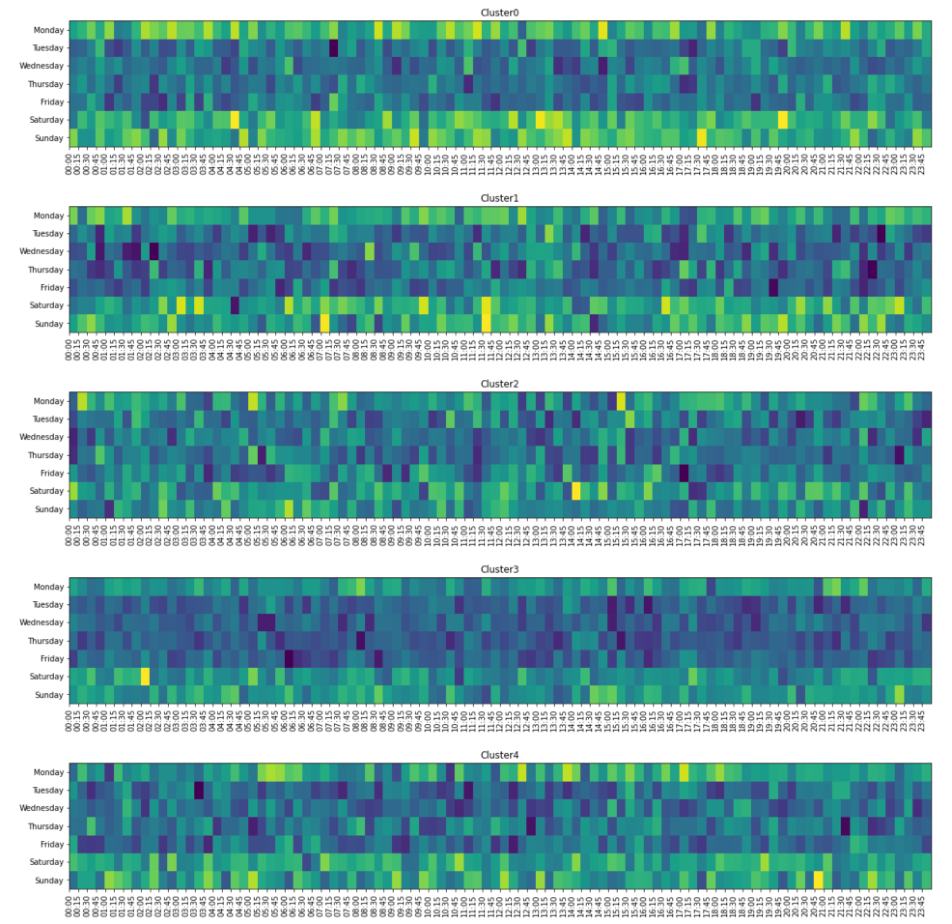

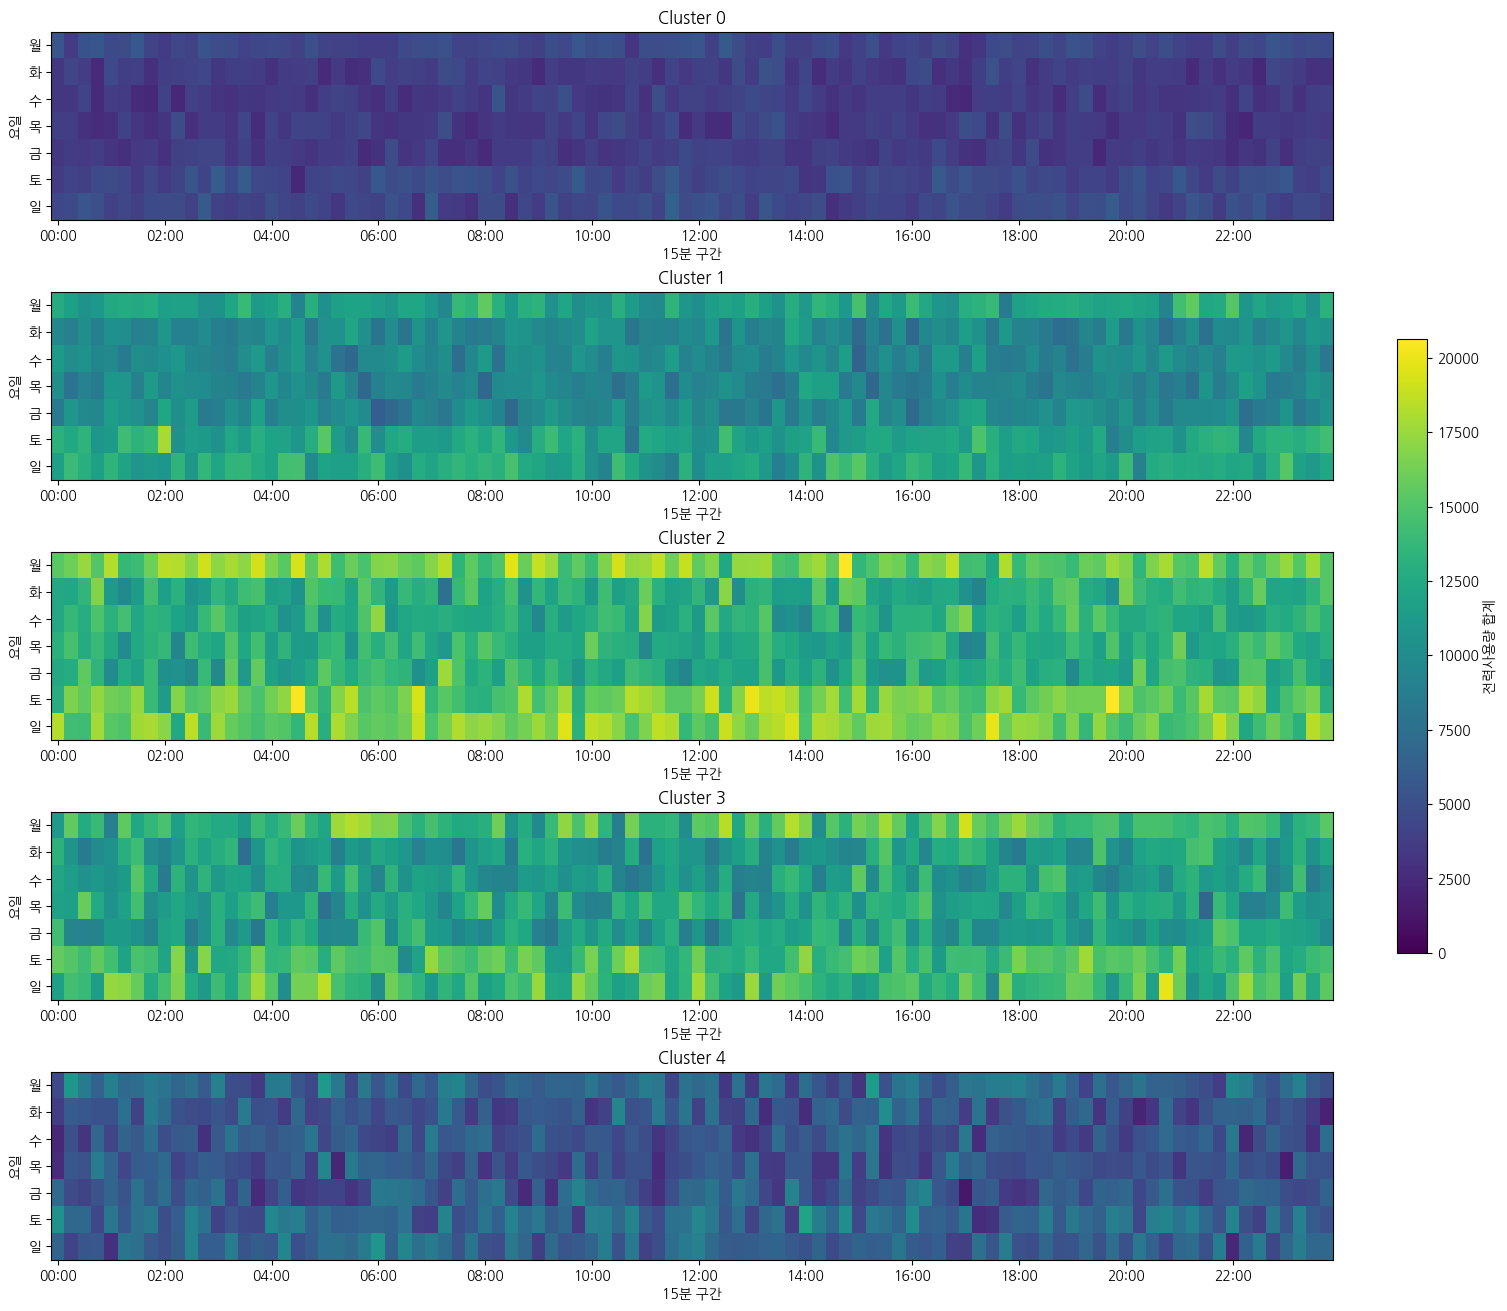

In [7]:
quarter['weekday']=quarter.date.dt.dayofweek;quarter['slot']=quarter.date.dt.hour*4+quarter.date.dt.minute//15
matrices={};support={}
for k in range(5):
    z=quarter[quarter.Cluster==k]
    matrices[k]=z.pivot_table(index='weekday',columns='slot',values='power consumption sum',aggfunc='sum',fill_value=0).reindex(index=range(7),columns=range(96),fill_value=0)
    support[k]=z.groupby(['weekday','slot']).size().unstack(fill_value=0).reindex(index=range(7),columns=range(96),fill_value=0)
    assert matrices[k].shape==(7,96)
    matrices[k].to_csv(OUT/('군집%d_요일15분_합계.csv'%k));support[k].to_csv(OUT/('군집%d_셀표본수.csv'%k))
fig,axs=plt.subplots(5,1,figsize=(15,13),constrained_layout=True)
vmax=max(z.to_numpy().max() for z in matrices.values())
for k,ax in enumerate(axs):
    im=ax.imshow(matrices[k],aspect='auto',cmap='viridis',vmin=0,vmax=vmax)
    ticks=np.arange(0,96,8);ax.set(yticks=range(7),yticklabels=['월','화','수','목','금','토','일'],xticks=ticks,
                                  xticklabels=['%02d:00'%(i//4) for i in ticks],title='Cluster %d'%k,xlabel='15분 구간',ylabel='요일')
fig.colorbar(im,ax=axs,label='전력사용량 합계',shrink=.5);plt.show()

## 3번 | 태양광 데이터

데이터 출처 : https://www.kaggle.com/cheedcheed/california-renewable-production-20102018

데이터 경로 : https://raw.githubusercontent.com/Datamanim/datarepo/main/adp/p2/problem3.csv

예측 변수 :SOLAR PV

### 3-1

> 데이터셋 분할 및 결과 검증
> 데이터셋 7:3 분할
> 데이터 전처리 및 예측 모델 생성
> 모델 성능 검증 : RMSE, R제곱, 정확도(아래 방식으로 연산)로 구하여라
> 정확도의 경우 실제값>예측값인 경우 (1-예측값/실제값), 실제값<예측값인 경우 (1-실제값/예측값)으로 하고 이것들을 평균낸 후 1에서 뺀값으로 한다.
> 분수식의 분모가 0인 경우의 정확도는 0.5로 취급한다.
> 최종 결과 제출 : 소수점 3째자리 반올림

**풀이 및 해석**

시간 순 7:3 분할로 평가합니다. SOLAR와 SOLAR THERMAL은 같은 시점의 SOLAR PV와 구성 관계가 있을 수 있으므로 예측 시점 누수를 피하기 위해 사용하지 않습니다. 캘린더·시간주기·직전 1시간 및 24시간 전 태양광을 입력으로 사용합니다. test는 과거 관측값이 매 시간 들어오는 한 스텝 예측 상황이며, 전체 미래 구간을 한 번에 예측하는 성능이 아닙니다. 문제의 정확도는 비음수 값에서 min(actual,pred)/max(actual,pred)의 평균과 같고, 양쪽 모두 0이면 0.5로 처리합니다.

시간 격자 복원으로 삽입한 누락 시점: 168
사용가능 자료: 44760 train: 31331 test: 13429 누락/lag 초기 제거: 312


RMSE      650.199
R2          0.959
문제 정확도      0.583
dtype: float64

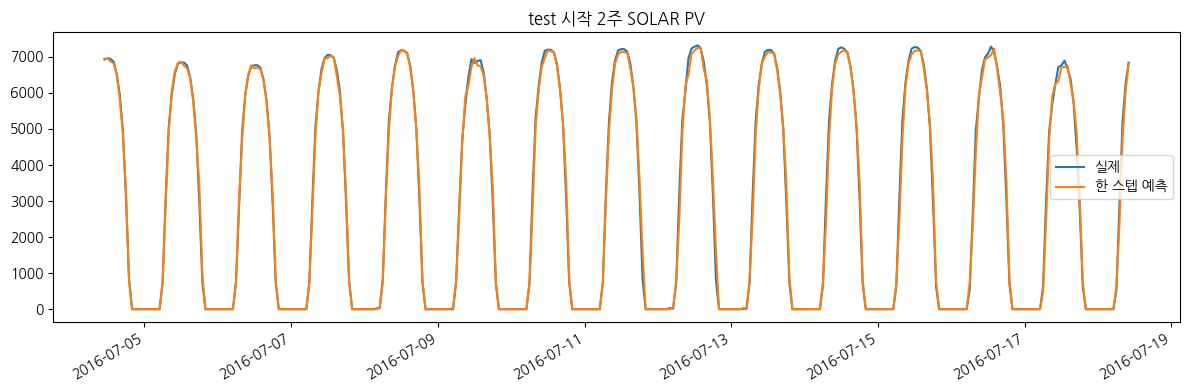

In [8]:
solar=load('problem3.csv');solar['TIMESTAMP']=pd.to_datetime(solar.TIMESTAMP);solar=solar.sort_values('TIMESTAMP').set_index('TIMESTAMP')
assert solar.index.is_unique
original_rows=len(solar)
solar=solar.asfreq('h')
print('시간 격자 복원으로 삽입한 누락 시점:',len(solar)-original_rows)
assert (solar.index.to_series().diff().dropna()==pd.Timedelta(hours=1)).all()
features=pd.DataFrame(index=solar.index)
features['hour_sin']=np.sin(2*np.pi*features.index.hour/24);features['hour_cos']=np.cos(2*np.pi*features.index.hour/24)
features['year_day_sin']=np.sin(2*np.pi*features.index.dayofyear/365.25);features['year_day_cos']=np.cos(2*np.pi*features.index.dayofyear/365.25)
features['lag1']=solar['SOLAR PV'].shift(1);features['lag24']=solar['SOLAR PV'].shift(24)
usable=solar['SOLAR PV'].notna() & features.notna().all(axis=1)
features=features[usable];actual=solar.loc[usable,'SOLAR PV'].to_numpy();cut=int(len(actual)*.7)
assert np.all(actual>=0)
model=Pipeline([('impute',SimpleImputer(strategy='median')),('model',RandomForestRegressor(n_estimators=120,max_depth=16,min_samples_leaf=2,random_state=SEED,n_jobs=1))])
model.fit(features.iloc[:cut],actual[:cut]);prediction=np.maximum(model.predict(features.iloc[cut:]),0)
truth=actual[cut:];denominator=np.maximum(truth,prediction)
ratio=np.divide(np.minimum(truth,prediction),denominator,out=np.full_like(truth,.5),where=denominator!=0)
custom_accuracy=float(ratio.mean())
print('사용가능 자료:',len(features),'train:',cut,'test:',len(truth),'누락/lag 초기 제거:',len(solar)-len(features))
metrics={'RMSE':np.sqrt(mean_squared_error(truth,prediction)),'R2':r2_score(truth,prediction),'문제 정확도':custom_accuracy}
display(pd.Series(metrics).round(3));pd.Series(metrics).round(3).to_csv(OUT/'태양광_최종평가.csv',header=['value'])
# 분모 0의 정의와 원문 분기식의 동치 검증
assert np.isclose(np.divide(0.,0.,out=np.array(.5),where=np.array(False)),.5)
example_a=np.array([4.,2.,0.,0.]);example_b=np.array([2.,4.,0.,2.]);exden=np.maximum(example_a,example_b)
np.testing.assert_allclose(np.divide(np.minimum(example_a,example_b),exden,out=np.full(4,.5),where=exden!=0),[.5,.5,.5,0.])
fig,ax=plt.subplots(figsize=(12,4));dates=features.index[cut:][:24*14]
ax.plot(dates,truth[:len(dates)],label='실제');ax.plot(dates,prediction[:len(dates)],label='한 스텝 예측');ax.set_title('test 시작 2주 SOLAR PV');ax.legend();fig.autofmt_xdate();fig.tight_layout();plt.show()

## 제출 전 확인

- 문항별 요구 산출물과 수치를 위 결과에서 확인합니다.
- 데이터 변형·모형·지표·가설의 조건을 답안과 함께 제출합니다.
- p ≥ 0.05는 귀무가설이 참임을 입증하는 것이 아니라 기각 근거 부족입니다.
- 모델 선택은 validation 결과로 했으며 최종 test 지표로 재튜닝하지 않습니다.
- 원문 표현의 모호성·자료의 오류는 풀이에서 명시하고 임의로 원문을 수정하지 않았습니다.